<a href="https://colab.research.google.com/github/aamyardra-rgb/ENERGIQ---Appliance_Energy_Consumption_Prediction_Application/blob/main/Appliances_Energy_Prediction_App.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,r2_score)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10,5)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
data=pd.read_csv('appliances_energy_consumption.csv')
df = pd.DataFrame(data)
df

,date,Appliances,lights,Kitchentemp,KHumidity_1,Living_temp,LH_2,Laundrytemp,LRH_3,Officetemp,...,ParentRtemp,PRH_9,T_outdoor,Atmos_Press_mm_hg,H_outdoor,Windspeed,Visibility,Tdewpoint,randvar1,randvar2
0,11-01-2016,60,30,19.890000,47.596667,19.200000,44.790000,19.790000,44.730000,19.000000,...,17.033333,45.5300,6.60,733.5,92.000000,7.000000,63.000000,5.3,13.275433,13.275433
1,11-01-2016,60,30,19.890000,46.693333,19.200000,44.722500,19.790000,44.790000,19.000000,...,17.066667,45.5600,6.48,733.6,92.000000,6.666667,59.166667,5.2,18.606195,18.606195
2,11-01-2016,50,30,19.890000,46.300000,19.200000,44.626667,19.790000,44.933333,18.926667,...,17.000000,45.5000,6.37,733.7,92.000000,6.333333,55.333333,5.1,28.642668,28.642668
3,11-01-2016,50,40,19.890000,46.066667,19.200000,44.590000,19.790000,45.000000,18.890000,...,17.000000,45.4000,6.25,733.8,92.000000,6.000000,51.500000,5.0,45.410390,45.410390
4,11-01-2016,60,40,19.890000,46.333333,19.200000,44.530000,19.790000,45.000000,18.890000,...,17.000000,45.4000,6.13,733.9,92.000000,5.666667,47.666667,4.9,10.084097,10.084097
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19730,27-05-2016,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.700000,...,23.200000,46.7900,22.70,755.2,55.666667,3.333333,23.666667,13.3,43.096812,43.096812
19731,27-05-2016,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.700000,...,23.200000,46.7900,22.60,755.2,56.000000,3.500000,24.500000,13.3,49.282940,49.282940
19732,27-05-2016,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.700000,...,23.200000,46.7900,22.50,755.2,56.333333,3.666667,25.333333,13.3,29.199117,29.199117
19733,27-05-2016,420,10,25.500000,46.990000,25.414000,43.036000,26.890000,41.290000,24.700000,...,23.200000,46.8175,22.30,755.2,56.666667,3.833333,26.166667,13.2,6.322784,6.322784


In [ ]:
df.shape

(19735, 29)

In [ ]:
df.head()

,date,Appliances,lights,Kitchentemp,KHumidity_1,Living_temp,LH_2,Laundrytemp,LRH_3,Officetemp,...,ParentRtemp,PRH_9,T_outdoor,Atmos_Press_mm_hg,H_outdoor,Windspeed,Visibility,Tdewpoint,randvar1,randvar2
0,11-01-2016,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,11-01-2016,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,11-01-2016,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,11-01-2016,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390
4,11-01-2016,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [ ]:
df.tail()

,date,Appliances,lights,Kitchentemp,KHumidity_1,Living_temp,LH_2,Laundrytemp,LRH_3,Officetemp,...,ParentRtemp,PRH_9,T_outdoor,Atmos_Press_mm_hg,H_outdoor,Windspeed,Visibility,Tdewpoint,randvar1,randvar2
19730,27-05-2016,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.7,...,23.2,46.7900,22.7,755.2,55.666667,3.333333,23.666667,13.3,43.096812,43.096812
19731,27-05-2016,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.7,...,23.2,46.7900,22.6,755.2,56.000000,3.500000,24.500000,13.3,49.282940,49.282940
19732,27-05-2016,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.7,...,23.2,46.7900,22.5,755.2,56.333333,3.666667,25.333333,13.3,29.199117,29.199117
19733,27-05-2016,420,10,25.500000,46.990000,25.414000,43.036000,26.890000,41.290000,24.7,...,23.2,46.8175,22.3,755.2,56.666667,3.833333,26.166667,13.2,6.322784,6.322784
19734,27-05-2016,430,10,25.500000,46.600000,25.264286,42.971429,26.823333,41.156667,24.7,...,23.2,46.8450,22.2,755.2,57.000000,4.000000,27.000000,13.2,34.118851,34.118851


In [ ]:
df.columns.to_list()

['date',
 'Appliances',
 'lights',
 'Kitchentemp',
 'KHumidity_1',
 'Living_temp',
 'LH_2',
 'Laundrytemp',
 'LRH_3',
 'Officetemp',
 'ORH_4',
 'Bathroomtemp',
 'BRH_5',
 'Outnorthtemp',
 'ONH_6',
 'IroningRtemp',
 'IRH_7',
 'TeenagerRtemp8',
 'TRH_8',
 'ParentRtemp',
 'PRH_9',
 'T_outdoor',
 'Atmos_Press_mm_hg',
 'H_outdoor',
 'Windspeed',
 'Visibility',
 'Tdewpoint',
 'randvar1',
 'randvar2']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date               19735 non-null  object 
 1   Appliances         19735 non-null  int64  
 2   lights             19735 non-null  int64  
 3   Kitchentemp        19735 non-null  float64
 4   KHumidity_1        19735 non-null  float64
 5   Living_temp        19735 non-null  float64
 6   LH_2               19735 non-null  float64
 7   Laundrytemp        19735 non-null  float64
 8   LRH_3              19735 non-null  float64
 9   Officetemp         19735 non-null  float64
 10  ORH_4              19735 non-null  float64
 11  Bathroomtemp       19735 non-null  float64
 12  BRH_5              19735 non-null  float64
 13  Outnorthtemp       19735 non-null  float64
 14  ONH_6              19735 non-null  float64
 15  IroningRtemp       19735 non-null  float64
 16  IRH_7              197

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.694958,102.524891,10.000000,50.000000,60.000000,100.000000,1080.000000
lights,19735.0,3.801875,7.935988,0.000000,0.000000,0.000000,0.000000,70.000000
Kitchentemp,19735.0,21.686571,1.606066,16.790000,20.760000,21.600000,22.600000,26.260000
KHumidity_1,19735.0,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.360000
Living_temp,19735.0,20.341219,2.192974,16.100000,18.790000,20.000000,21.500000,29.856667
LH_2,19735.0,40.420420,4.069813,20.463333,37.900000,40.500000,43.260000,56.026667
Laundrytemp,19735.0,22.267611,2.006111,17.200000,20.790000,22.100000,23.290000,29.236000
LRH_3,19735.0,39.242500,3.254576,28.766667,36.900000,38.530000,41.760000,50.163333
Officetemp,19735.0,20.855335,2.042884,15.100000,19.530000,20.666667,22.100000,26.200000
ORH_4,19735.0,39.026904,4.341321,27.660000,35.530000,38.400000,42.156667,51.090000


In [ ]:
df.isna().sum()

,0
date,0
Appliances,0
lights,0
Kitchentemp,0
KHumidity_1,0
Living_temp,0
LH_2,0
Laundrytemp,0
LRH_3,0
Officetemp,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop(columns=['randvar1', 'randvar2'], inplace=True, errors='ignore')

In [ ]:
df.shape

(19735, 27)

In [ ]:
df['date']=pd.to_datetime(df['date'],format='%d-%m-%Y')

df['date'].dtype
df['date'].head()

,date
0,2016-01-11
1,2016-01-11
2,2016-01-11
3,2016-01-11
4,2016-01-11


In [ ]:
df['day_of_week']=df['date'].dt.dayofweek
df['month']=df['date'].dt.month

df[['date','day_of_week','month']].head()


,date,day_of_week,month
0,2016-01-11,0,1
1,2016-01-11,0,1
2,2016-01-11,0,1
3,2016-01-11,0,1
4,2016-01-11,0,1


In [ ]:
df['Appliances'].describe()

,Appliances
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000


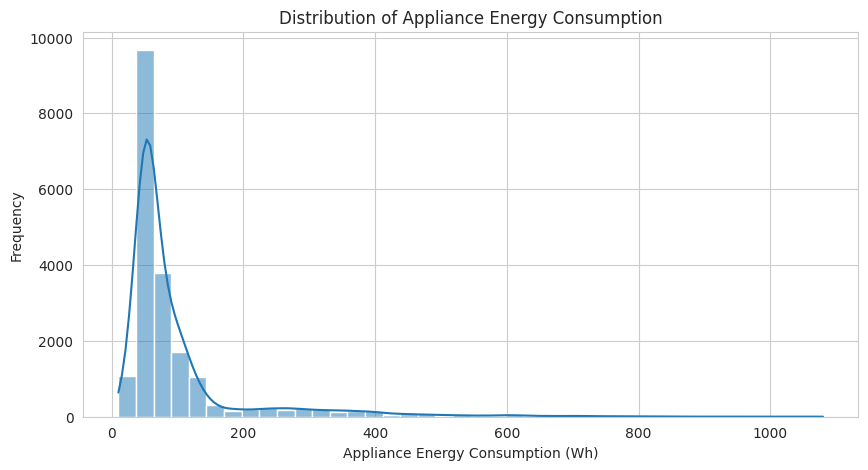

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['Appliances'],bins=40,kde=True
)

plt.title("Distribution of Appliance Energy Consumption")
plt.xlabel("Appliance Energy Consumption (Wh)")
plt.ylabel("Frequency")

plt.show()

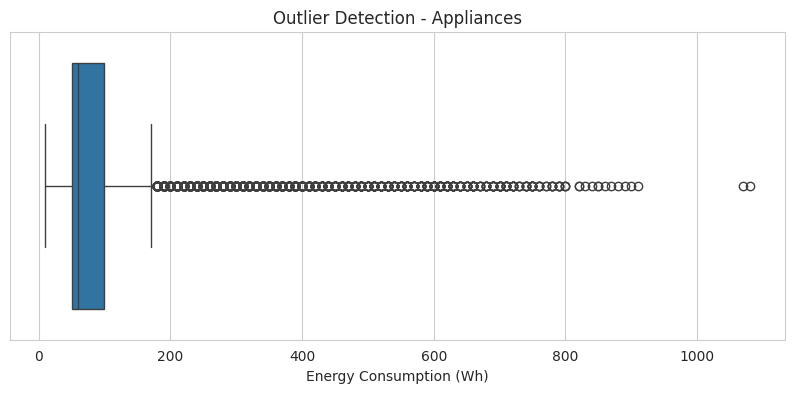

In [ ]:
plt.figure(figsize=(10,4))

sns.boxplot(x=df['Appliances'])

plt.title("Outlier Detection - Appliances")
plt.xlabel("Energy Consumption (Wh)")
plt.show()

In [ ]:
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df['Appliances']< lower_limit) | (df['Appliances']> upper_limit)]

print("Lower Limit:",lower_limit)
print("Upper Limit:",upper_limit)

print("Number of potential outliers:",len(outliers))

Lower Limit: -25.0
Upper Limit: 175.0
Number of potential outliers: 2138


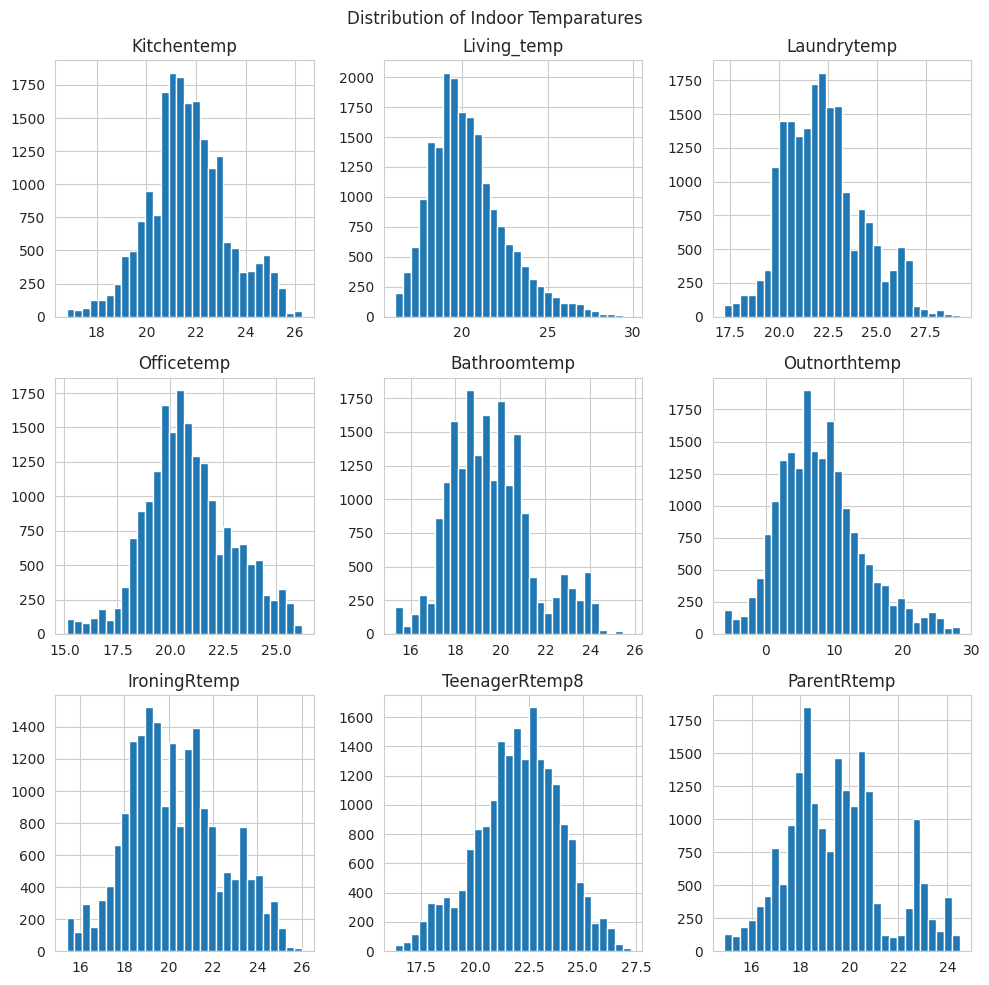

In [ ]:
# Indoor temparature analysis
temperature_columns = [
    'Kitchentemp',
    'Living_temp',
    'Laundrytemp',
    'Officetemp',
    'Bathroomtemp',
    'Outnorthtemp',
    'IroningRtemp',
    'TeenagerRtemp8',
    'ParentRtemp'
]

df[temperature_columns].hist(figsize=(10,10),bins=30)

plt.suptitle('Distribution of Indoor Temparatures')
plt.tight_layout()
plt.show()

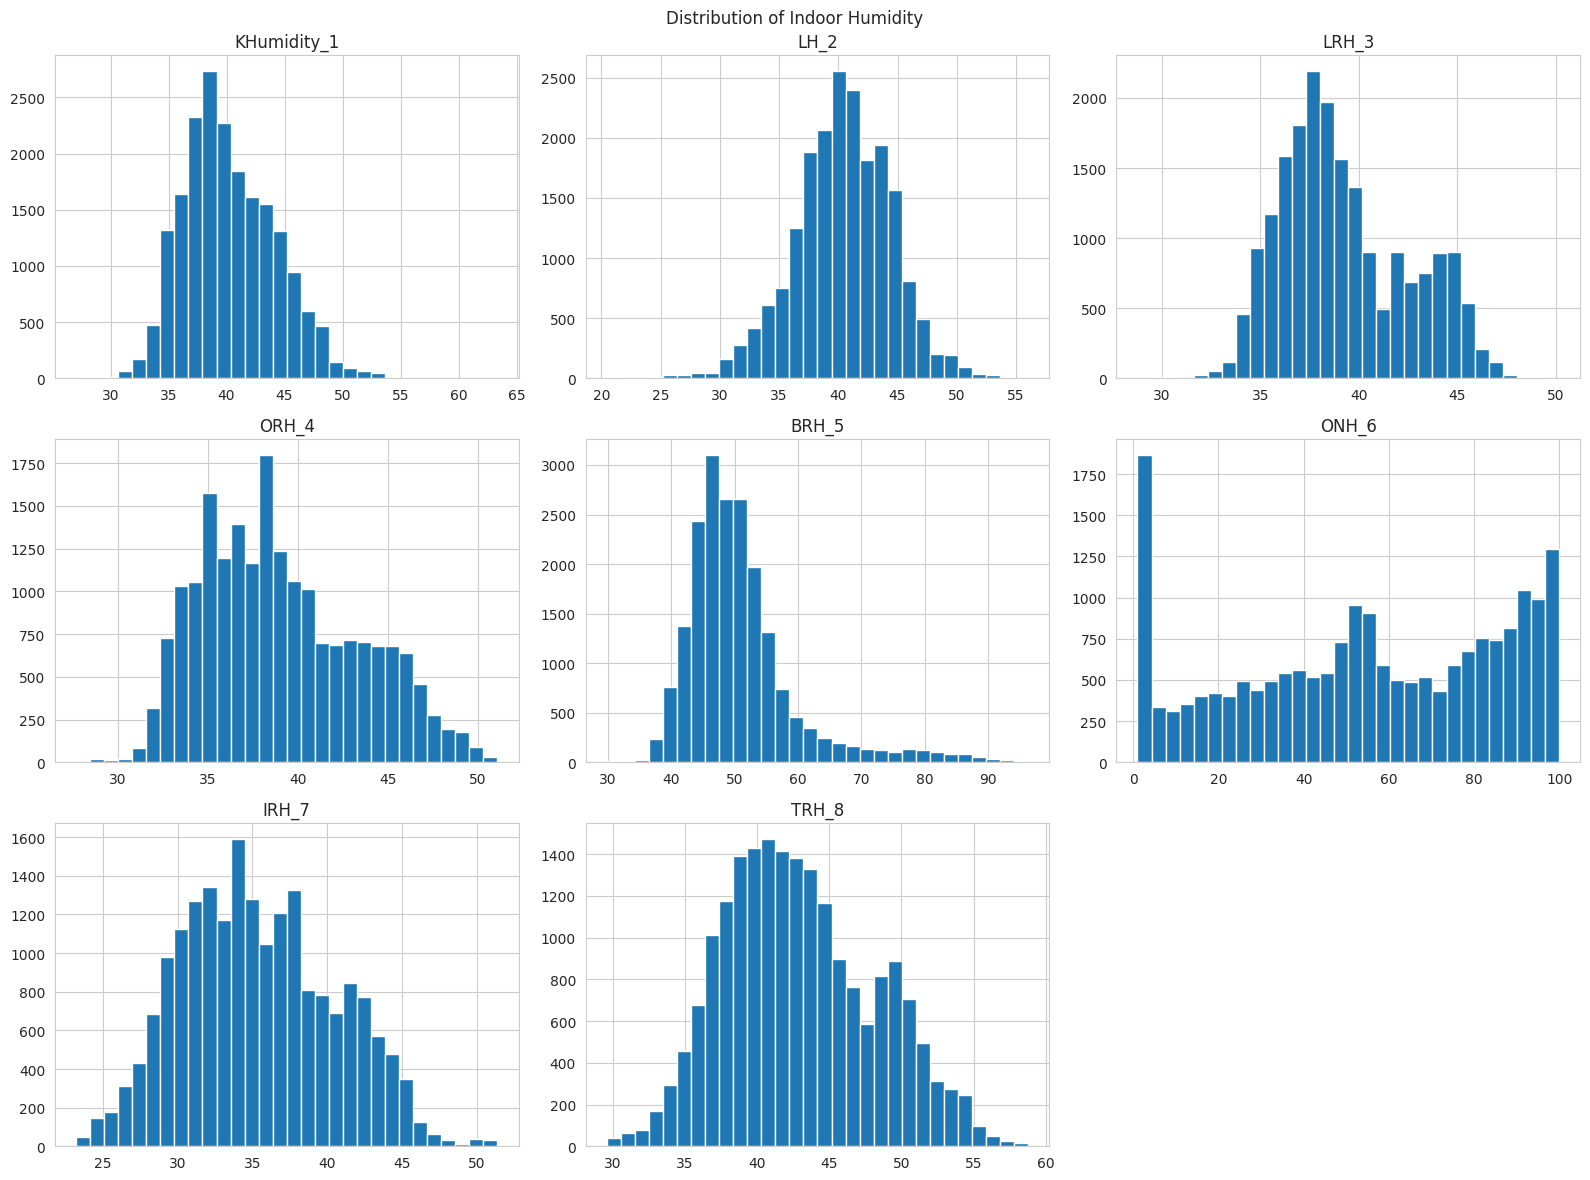

In [ ]:
# Indoor humidity analysis
humidity_columns = [
    'KHumidity_1',
    'LH_2',
    'LRH_3',
    'ORH_4',
    'BRH_5',
    'ONH_6',
    'IRH_7',
    'TRH_8',
]

df[humidity_columns].hist(figsize=(16,12),bins=30)
plt.suptitle('Distribution of Indoor Humidity')
plt.tight_layout()
plt.show()

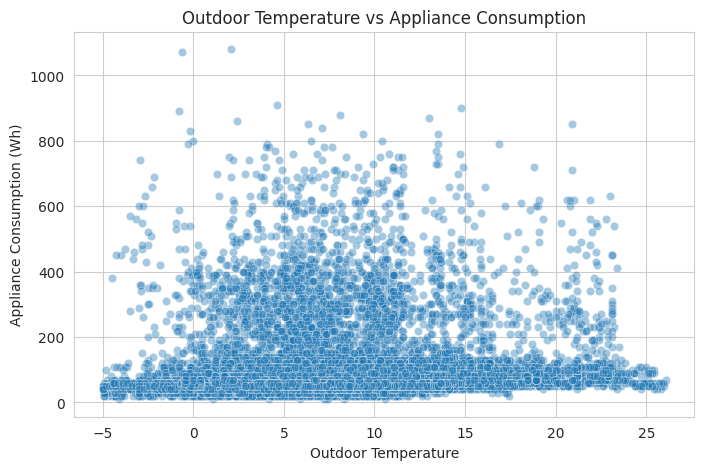

In [ ]:
# Outdoor temperature vs appliance consumption
plt.figure(figsize=(8,5))

sns.scatterplot(data=df,x='T_outdoor',y='Appliances',alpha=0.4)

plt.title("Outdoor Temperature vs Appliance Consumption")
plt.xlabel("Outdoor Temperature")
plt.ylabel('Appliance Consumption (Wh)')
plt.show()


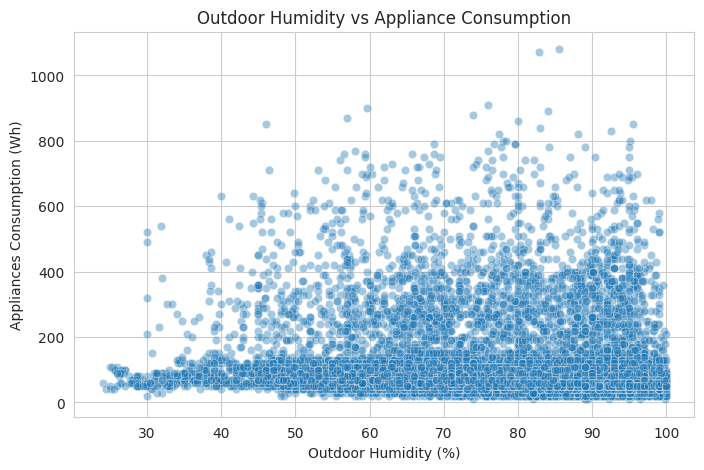

In [ ]:
#Outdoor Humidity vs Appliance Consumption
plt.figure(figsize=(8,5))

sns.scatterplot(data=df,x='H_outdoor',y='Appliances',alpha=0.4)

plt.title("Outdoor Humidity vs Appliance Consumption")
plt.xlabel("Outdoor Humidity (%)")
plt.ylabel("Appliances Consumption (Wh)")

plt.show()

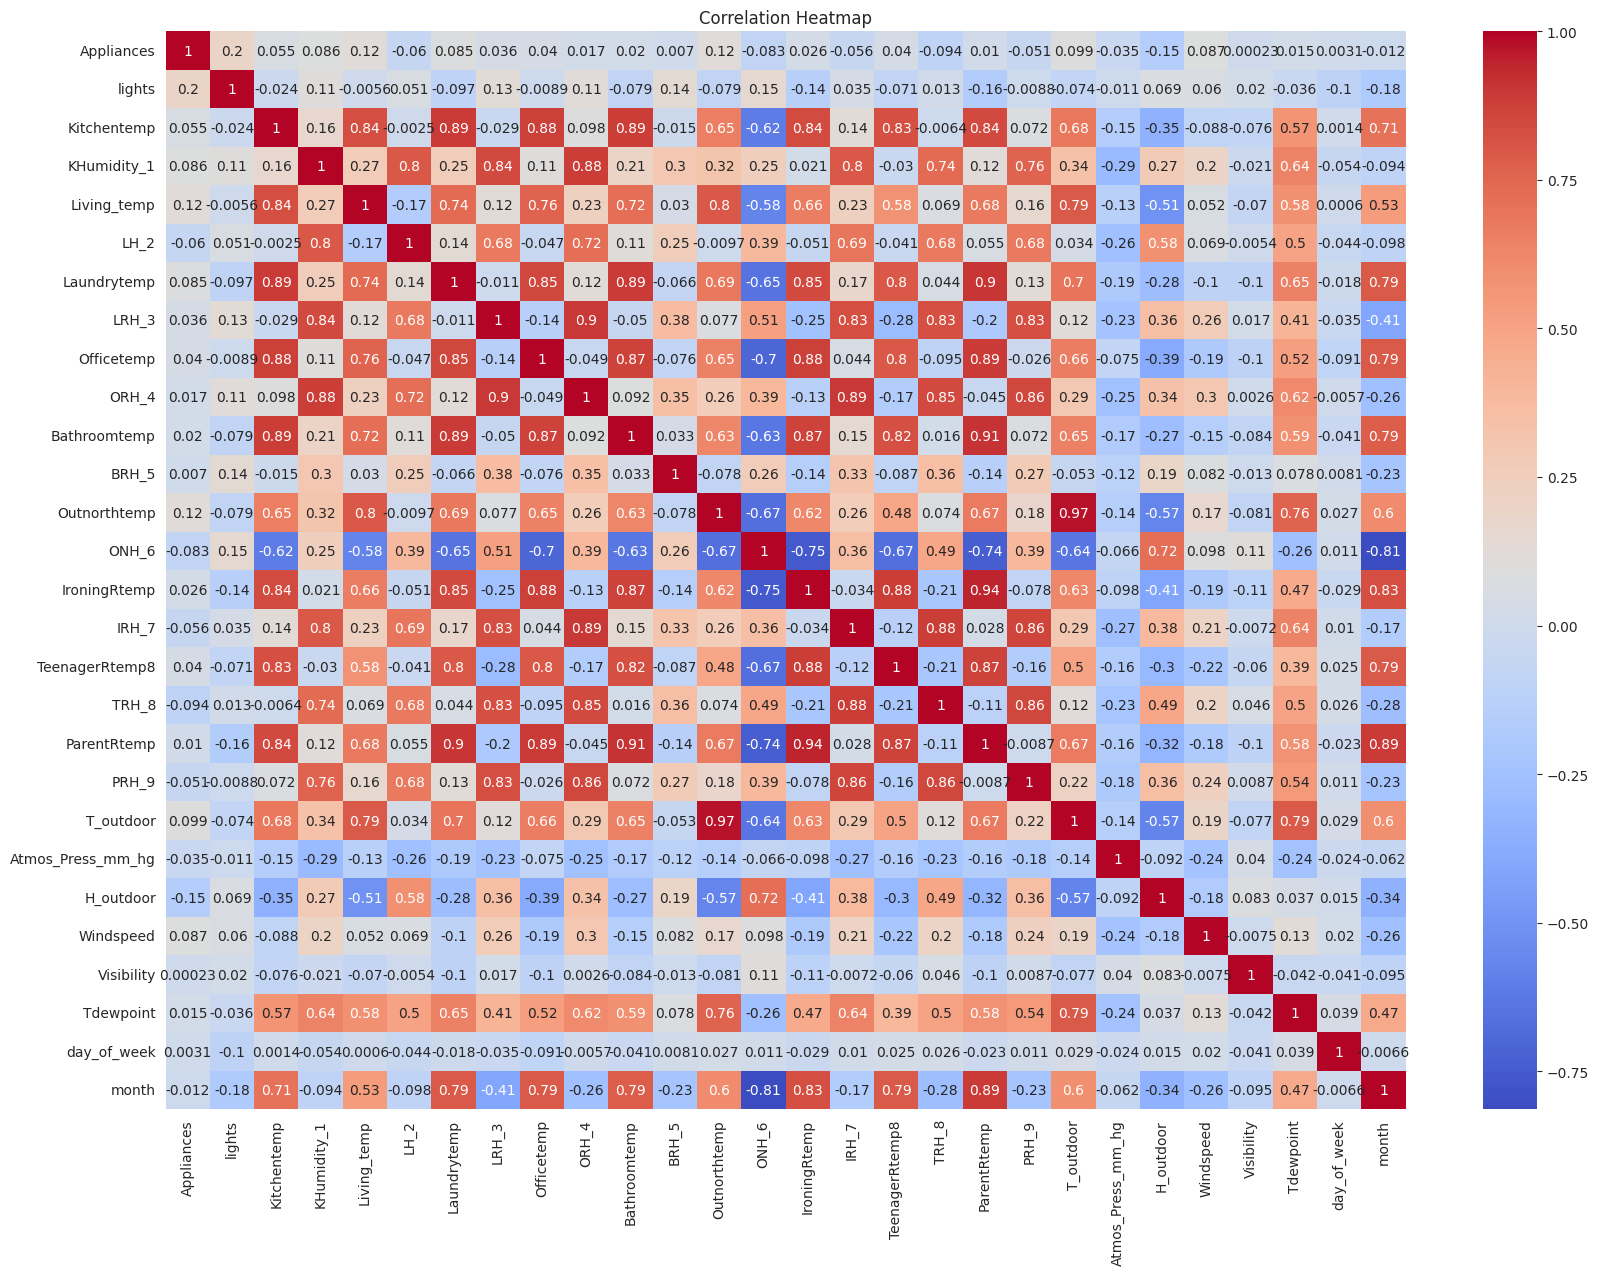

In [ ]:

# Correlation Heatmap

df.corr(numeric_only=True)

plt.figure(figsize=(20,14))

sns.heatmap(df.corr(numeric_only=True),cmap='coolwarm',annot=True)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
appliance_corr = df['Appliances'].sort_values(ascending=False)
appliance_corr

,Appliances
731,1080
1451,1070
432,910
12088,900
1452,890
...,...
5709,10
5859,10
6558,10
1079,10


In [ ]:
# Feature Selection
y=df['Appliances']
y

,Appliances
0,60
1,60
2,50
3,50
4,60
...,...
19730,100
19731,90
19732,270
19733,420


In [ ]:
x = df.drop('Appliances', axis=1)
y = df['Appliances']

print("Input Features:", x.shape)
print("Target:", y.shape)

Input Features: (19735, 28)
Target: (19735,)


In [ ]:

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)



In [ ]:
# Drop the 'date' column as it cannot be scaled by StandardScaler
x_train = x_train.drop(columns=['date'], errors='ignore')
x_test = x_test.drop(columns=['date'], errors='ignore')


In [ ]:
df.drop(['date'],axis = True,inplace=True)

In [ ]:
df.columns

Index(['Appliances', 'lights', 'Kitchentemp', 'KHumidity_1', 'Living_temp',
       'LH_2', 'Laundrytemp', 'LRH_3', 'Officetemp', 'ORH_4', 'Bathroomtemp',
       'BRH_5', 'Outnorthtemp', 'ONH_6', 'IroningRtemp', 'IRH_7',
       'TeenagerRtemp8', 'TRH_8', 'ParentRtemp', 'PRH_9', 'T_outdoor',
       'Atmos_Press_mm_hg', 'H_outdoor', 'Windspeed', 'Visibility',
       'Tdewpoint', 'day_of_week', 'month'],
      dtype='object')

In [ ]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:

# Train and predict with the updated scaled variables
lr_model = LinearRegression()
lr_model.fit(x_train, y_train)

lr_pred = lr_model.predict(x_test)
print("Linear regression completed successfully!")

Linear regression completed successfully!


In [ ]:
rf_model = RandomForestRegressor(n_estimators=200,
                           max_depth=None,
                           min_samples_split=2,
                           min_samples_leaf=1,
                           random_state=42,n_jobs=-1
)

rf_model.fit(x_train,y_train)
rf_pred=rf_model.predict(x_test)

print("Random forest completed")

Random forest completed


In [ ]:
dt_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(x_train,y_train)
dt_pred =dt_model.predict(x_test)

print("Decision tree completed")


Decision tree completed


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(
    n_neighbors=5,
    weights='distance'
)

knn_model.fit(x_train, y_train)

knn_pred = knn_model.predict(x_test)

print("KNN Regression completed")


KNN Regression completed


In [ ]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = mean_absolute_percentage_error(actual, predicted)

    r2 = r2_score(actual, predicted)

    return {
        'Model': name,
        'MAE': mae,
        'MAPE':mape,
        'RMSE': rmse,
        'R2 Score': r2
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        lr_pred
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_pred
    )
)

results.append(
    evaluate_model(
        "KNN",
        y_test,
        knn_pred
    )
)

results_df = pd.DataFrame(results)

print(results_df)

               Model        MAE      MAPE       RMSE  R2 Score
0  Linear Regression  52.605306  0.628707  91.188683  0.169052
1      Random Forest  31.548569  0.322116  67.481511  0.544947
2      Decision Tree  44.023299  0.475228  86.781174  0.247436
3                KNN  30.838416  0.292293  68.194397  0.535282


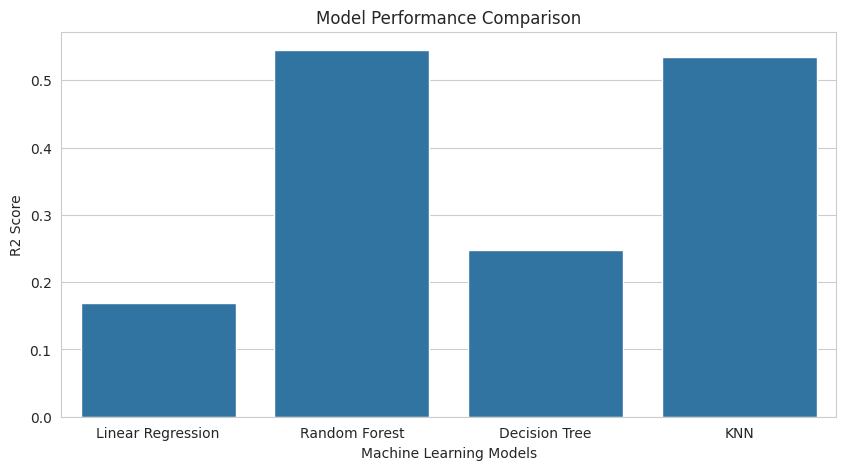

In [ ]:
# Visualize model comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("Model Performance Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Machine Learning Models")

plt.show()

In [ ]:
# Make a new prediction
new_data = pd.DataFrame([{
    'Kitchentemp': 22.0,
    'KHumidity_1': 45.0,
    'Living_temp': 21.0,
    'LH_2': 48.0,
    'Laundrytemp': 20.0,
    'LRH_3': 50.0,
    'Officetemp': 21.0,
    'ORH_4': 45.0,
    'Bathroomtemp': 22.0,
    'BRH_5': 55.0,
    'Outnorthtemp': 18.0,
    'ONH_6': 60.0,
    'IroningRtemp': 20.0,
    'IRH_7': 42.0,
    'TeenagerRtemp8': 21.0,
    'TRH_8': 48.0,
    'ParentRtemp': 20.0,
    'PRH_9': 45.0,
    'T_outdoor': 15.0,
    'H_outdoor': 70.0,
    'Atmos_Press_mm_hg': 740.0,
    'Windspeed': 3.0,
    'Visibility': 40.0,
    'Tdewpoint': 10.0,
    'day_of_week': 2,
    'month': 11,
    'lights':40
}])

prediction = rf_model.predict(new_data)

print(
    "Predicted Appliance Energy Consumption:",
    round(prediction[0], 2),
    "Wh"
)

Predicted Appliance Energy Consumption: 275.65 Wh


In [ ]:
# Convert Wh to kWh
predicted_kwh = prediction[0] / 1000

print("Predicted Energy Consumption:",
      round(prediction[0], 2), "Wh")

print("Predicted Energy Consumption:",
      round(predicted_kwh, 4), "kWh")

Predicted Energy Consumption: 275.65 Wh
Predicted Energy Consumption: 0.2756 kWh


In [ ]:
# Evaluate your Random Forest model

rf_predictions = rf_model.predict(x_test)

mae = mean_absolute_error(
    y_test, rf_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

mape = mean_absolute_percentage_error(y_test,rf_predictions)

r2 = r2_score(
    y_test, rf_predictions
)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2))
print("R2 Score:", round(r2, 4))

Random Forest Evaluation
------------------------
MAE: 31.55
RMSE: 67.48
MAPE: 0.32
R2 Score: 0.5449


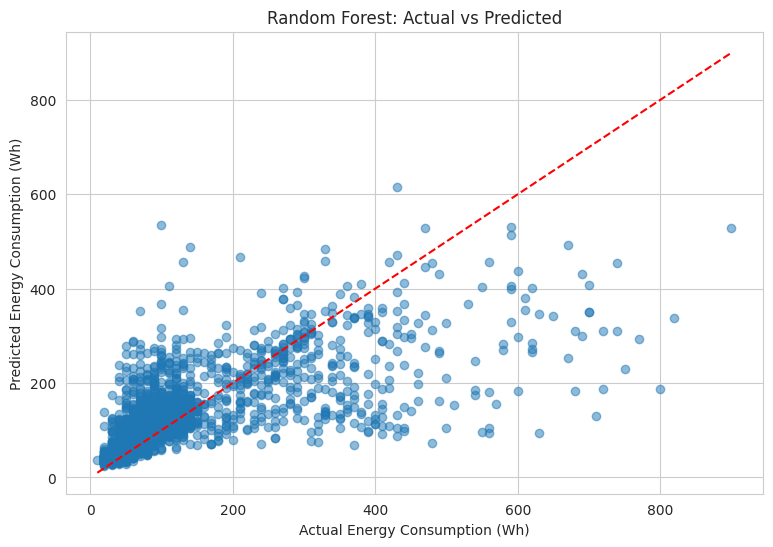

In [ ]:
# Actual vs Predicted visualization
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.5
)

minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.xlabel("Actual Energy Consumption (Wh)")
plt.ylabel("Predicted Energy Consumption (Wh)")

plt.title("Random Forest: Actual vs Predicted")

plt.show()

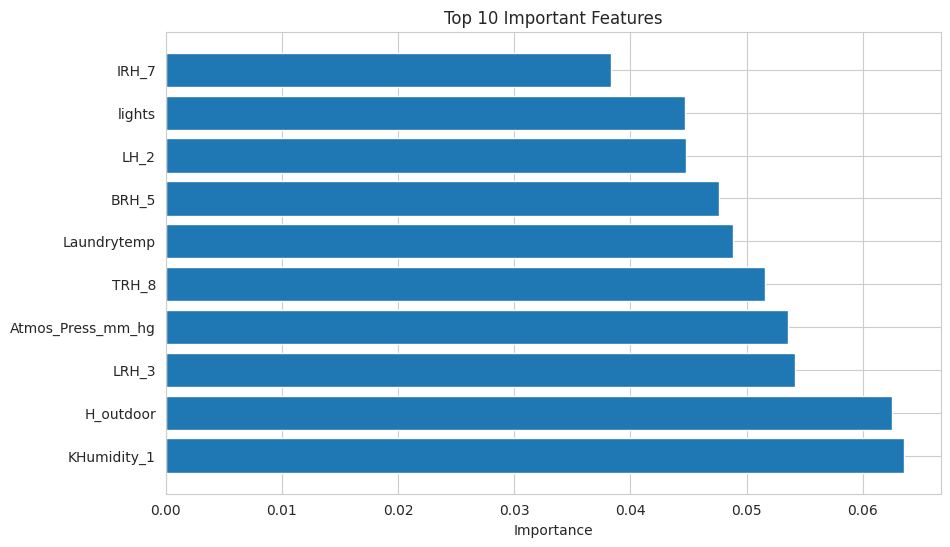

In [ ]:
# Get columns excluding 'date' to match the features used for training
trained_features = x.drop(columns=['date'], errors='ignore').columns

feature_importance = pd.DataFrame({
    "Feature": trained_features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))
plt.barh(
    feature_importance["Feature"][:10],
    feature_importance["Importance"][:10]
)
plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.show()

In [ ]:
import pickle

pickle.dump(
    rf_model,
    open('energy_model.pkl','wb')
)

pickle.dump(
    scaler,
    open('scaler.pkl','wb')
)

print("Model Saved")

Model Saved


In [ ]:
print(x.columns.tolist())


['date', 'lights', 'Kitchentemp', 'KHumidity_1', 'Living_temp', 'LH_2', 'Laundrytemp', 'LRH_3', 'Officetemp', 'ORH_4', 'Bathroomtemp', 'BRH_5', 'Outnorthtemp', 'ONH_6', 'IroningRtemp', 'IRH_7', 'TeenagerRtemp8', 'TRH_8', 'ParentRtemp', 'PRH_9', 'T_outdoor', 'Atmos_Press_mm_hg', 'H_outdoor', 'Windspeed', 'Visibility', 'Tdewpoint', 'day_of_week', 'month']
